# Student Performance EDA: County Education Office
**Question:** which learners are most at risk of poor performance, and what is associated with better results?
Data: `student_performance.csv`, produced by `generate_data.py` (1,200 students, seed 55). Sections: Structure, Univariate, Bivariate, Multivariate, Hypotheses, then Findings, Recommendations and Limitations.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
if not os.path.exists('student_performance.csv'):
    exec(open('generate_data.py').read())
df = pd.read_csv('student_performance.csv')
SUBJECTS = ['math', 'english', 'science']

## 1. Structure
The grain is **one row per student** (`student_id` is the unique key). Categorical: `county`, `school_type`, `gender`. Numerical: `attendance_rate` (a 0-1 proportion), `study_hours` (hours per week, assumed), and three subject scores (`math`, `english`, `science`, 0-100).

In [2]:
print(df.shape); print(df.dtypes); df.head()

(1200, 9)
student_id           int64
county                 str
school_type            str
gender                 str
attendance_rate    float64
study_hours        float64
math               float64
english            float64
science            float64
dtype: object


,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science
0,1,Turkana,Private,M,0.77,6.5,81.0,71.0,73.0
1,2,Nyeri,Private,M,0.97,8.5,100.0,86.0,90.0
2,3,Nyeri,Private,F,0.98,8.0,82.0,89.0,90.0
3,4,Turkana,Public,M,0.93,6.0,83.0,91.0,72.0
4,5,Kisumu,Private,F,0.67,6.1,76.0,69.0,62.0


In [3]:
print('Missing values:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum(), '| duplicate IDs:', df.student_id.duplicated().sum())
print('Scores outside 0-100:', ((df[SUBJECTS] < 0) | (df[SUBJECTS] > 100)).sum().sum())
print('attendance_rate outside 0-1:', ((df.attendance_rate < 0) | (df.attendance_rate > 1)).sum())
print('Negative study_hours:', (df.study_hours < 0).sum())
print('Scores sitting exactly at the 100 ceiling:', (df[SUBJECTS] == 100).sum().to_dict())

Missing values: 0
Duplicate rows: 0 | duplicate IDs: 0
Scores outside 0-100: 0
attendance_rate outside 0-1: 0
Negative study_hours: 0
Scores sitting exactly at the 100 ceiling: {'math': 11, 'english': 21, 'science': 16}


No missing values, duplicates or out-of-range values, so no cleaning is needed. One thing to remember: some scores sit exactly at the 100 ceiling (the generator clips at 100), so very high scores are slightly compressed.

Now we create `average_score` and `performance_band` (At Risk < 60, Meeting 60-74, Exceeding >= 75).

In [4]:
df['average_score'] = df[SUBJECTS].mean(axis=1)
df['performance_band'] = pd.cut(df['average_score'], bins=[-np.inf, 60, 75, np.inf],
                                labels=['At Risk', 'Meeting', 'Exceeding'], right=False)
df[['student_id', 'average_score', 'performance_band']].head()

,student_id,average_score,performance_band
0,1,75.0,Exceeding
1,2,92.0,Exceeding
2,3,87.0,Exceeding
3,4,82.0,Exceeding
4,5,69.0,Meeting


## 2. Univariate

In [5]:
num = ['attendance_rate', 'study_hours'] + SUBJECTS + ['average_score']
s = df[num].describe().T[['mean', '50%', 'std', 'min', 'max']]
s['skew'] = df[num].skew()
s.round(2)

,mean,50%,std,min,max,skew
attendance_rate,0.80,0.82,0.12,0.33,1.0,-0.86
study_hours,5.08,4.50,3.03,0.20,23.3,1.17
math,71.89,72.00,10.86,37.00,100.0,0.10
english,74.52,74.00,10.49,47.00,100.0,0.16
science,69.61,69.00,12.02,35.00,100.0,0.11
average_score,72.01,71.67,9.11,48.33,100.0,0.26


Centre, spread and shape: scores are close to symmetric (skew about 0.1 to 0.2) with means of roughly 70-75 and standard deviations of 10-12 points. `attendance_rate` is left-skewed (most students attend 73-90% of the time, with a tail of low attenders). `study_hours` is right-skewed (median 4.5, mean 5.1).

In [6]:
for c in ['gender', 'county', 'school_type', 'performance_band']:
    t = pd.DataFrame({'count': df[c].value_counts(), 'share_%': (df[c].value_counts(normalize=True) * 100).round(1)})
    print(t, '\n')

        count  share_%
gender                
F         612     51.0
M         588     49.0 

         count  share_%
county                 
Mombasa    212     17.7
Kisumu     208     17.3
Nyeri      203     16.9
Nakuru     202     16.8
Turkana    191     15.9
Nairobi    184     15.3 

             count  share_%
school_type                
Public         866     72.2
Private        334     27.8 

                  count  share_%
performance_band                
Meeting             672     56.0
Exceeding           429     35.8
At Risk              99      8.2 



In [7]:
q1, q3 = df.study_hours.quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outl = df[(df.study_hours < lo) | (df.study_hours > hi)]
print(f'IQR fence: {lo:.1f} to {hi:.1f} hours | outliers: {len(outl)} (max {df.study_hours.max()} hours)')
outl[['student_id', 'study_hours', 'average_score']].sort_values('study_hours', ascending=False).head(10)

IQR fence: -2.8 to 12.4 hours | outliers: 29 (max 23.3 hours)


,student_id,study_hours,average_score
835,836,23.3,99.666667
690,691,18.7,93.666667
1135,1136,17.8,96.666667
271,272,17.1,89.333333
614,615,16.2,93.666667
434,435,16.2,90.666667
310,311,15.5,96.000000
364,365,15.3,95.333333
94,95,15.2,95.666667
768,769,15.0,85.333333


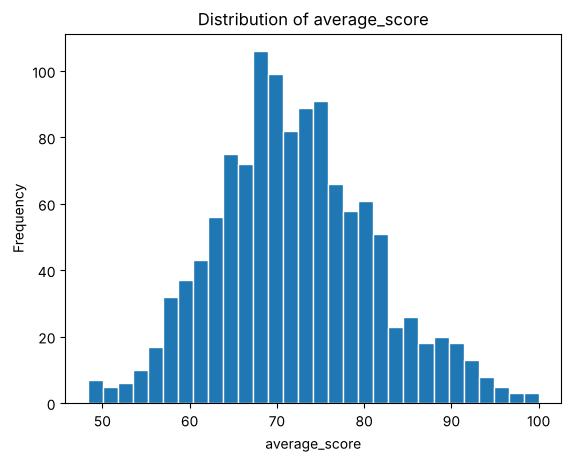

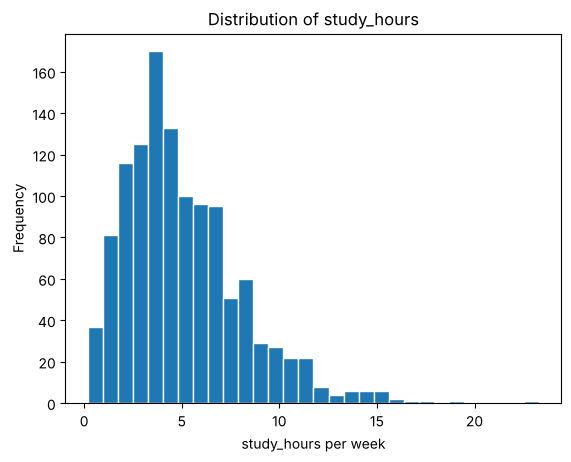

In [8]:
ax = df['average_score'].plot(kind='hist', bins=30, edgecolor='white', title='Distribution of average_score')
ax.set_xlabel('average_score'); plt.savefig('hist_average_score.png', dpi=120, bbox_inches='tight'); plt.show()
ax = df['study_hours'].plot(kind='hist', bins=30, edgecolor='white', title='Distribution of study_hours')
ax.set_xlabel('study_hours per week'); plt.savefig('hist_study_hours.png', dpi=120, bbox_inches='tight'); plt.show()

Saved: `hist_average_score.png` and `hist_study_hours.png`. Average score is centred at 72, so only a small group falls below 60. Study hours has a long right tail: **29 students lie above the 12.4-hour fence, up to 23.3 hours**. These are plausible for a gamma-shaped variable, so they are kept, and we test sensitivity to them in Hypotheses.

## 3. Bivariate

In [9]:
corr = df[['attendance_rate', 'study_hours'] + SUBJECTS + ['average_score']].corr().round(2)
corr

,attendance_rate,study_hours,math,english,science,average_score
attendance_rate,1.00,-0.03,0.30,0.33,0.26,0.36
study_hours,-0.03,1.00,0.56,0.62,0.55,0.70
math,0.30,0.56,1.00,0.56,0.46,0.81
english,0.33,0.62,0.56,1.00,0.50,0.83
science,0.26,0.55,0.46,0.50,1.00,0.82
average_score,0.36,0.70,0.81,0.83,0.82,1.00


In [10]:
corr['average_score'].drop('average_score').sort_values(ascending=False)

english            0.83
science            0.82
math               0.81
study_hours        0.70
attendance_rate    0.36
Name: average_score, dtype: float64

**Three strongest relationships with `average_score`:** `english` (r = 0.83), `science` (0.82) and `math` (0.81). These are *mechanical*, because they are the components of the average, so they say nothing about causes. The strongest genuine factor is **`study_hours` (r = 0.70)**, a strong positive relationship, followed by **`attendance_rate` (r = 0.36)**, a moderate positive one. Correlation is not causation.

In [11]:
print(df.groupby('gender').average_score.mean().round(1), '\n')
print(df.groupby('school_type').average_score.mean().round(1), '\n')
print(df.groupby('county').average_score.mean().round(1).sort_values())

gender
F    72.1
M    71.9
Name: average_score, dtype: float64 

school_type
Private    76.0
Public     70.5
Name: average_score, dtype: float64 

county
Turkana    71.0
Nakuru     71.8
Nyeri      71.9
Nairobi    72.0
Mombasa    72.2
Kisumu     73.1
Name: average_score, dtype: float64


         at_risk_%  at_risk_n  students
county                                 
Nairobi        9.2         17       184
Mombasa        9.0         19       212
Nyeri          8.9         18       203
Kisumu         8.2         17       208
Turkana        7.9         15       191
Nakuru         6.4         13       202


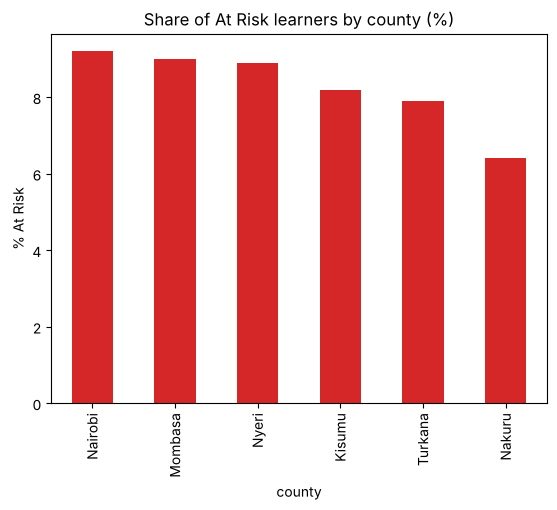

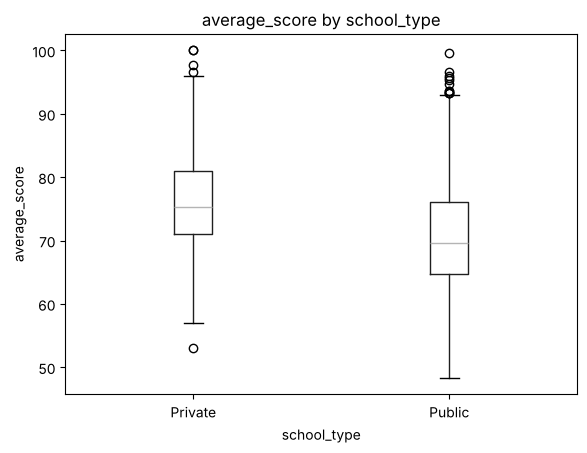

In [12]:
share = (pd.crosstab(df.county, df.performance_band, normalize='index')['At Risk'] * 100).round(1).sort_values(ascending=False)
counts = df[df.performance_band == 'At Risk'].county.value_counts()
print(pd.DataFrame({'at_risk_%': share, 'at_risk_n': counts, 'students': df.county.value_counts()}).loc[share.index])
ax = share.plot(kind='bar', title='Share of At Risk learners by county (%)', color='tab:red')
ax.set_ylabel('% At Risk'); plt.savefig('bar_at_risk_by_county.png', dpi=120, bbox_inches='tight'); plt.show()
ax = df.boxplot(column='average_score', by='school_type', grid=False)
plt.suptitle(''); plt.title('average_score by school_type'); plt.ylabel('average_score')
plt.savefig('box_score_by_school_type.png', dpi=120, bbox_inches='tight'); plt.show()

Saved: `figures/bar_at_risk_by_county.png` and `figures/box_score_by_school_type.png`. **Nairobi has the highest share of At Risk learners (9.2%)**, but the spread across counties is narrow (6.4% in Nakuru to 9.2%), with only 13-19 At Risk students per county. County average scores range only from 71.0 (Turkana) to 73.1 (Kisumu), and gender averages differ by 0.2 points. School type is the one category with a clear gap: Private averages 76.0 against 70.5 for Public. We test whether the county differences are real in Hypotheses.

## 4. Multivariate
Does the school-type gap persist once we hold attendance and study effort roughly constant?

In [13]:
df['attendance_band'] = pd.cut(df.attendance_rate, [0, .70, .85, 1.01], labels=['<70%', '70-84%', '85%+'], right=False)
df['study_quartile'] = pd.qcut(df.study_hours, 4, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])
p1 = df.pivot_table('average_score', 'attendance_band', 'school_type', observed=True).round(1)
p1['gap (Private-Public)'] = (p1['Private'] - p1['Public']).round(1)
p2 = df.pivot_table('average_score', 'study_quartile', 'school_type', observed=True).round(1)
p2['gap (Private-Public)'] = (p2['Private'] - p2['Public']).round(1)
print(p1, '\n'); print(p2, '\n')
print(df.pivot_table('average_score', 'attendance_band', 'school_type', aggfunc='count', observed=True))

school_type      Private  Public  gap (Private-Public)
attendance_band                                       
<70%                71.1    64.9                   6.2
70-84%              75.6    69.2                   6.4
85%+                78.7    73.9                   4.8 

school_type     Private  Public  gap (Private-Public)
study_quartile                                       
Q1 (lowest)        69.5    63.8                   5.7
Q2                 74.9    67.1                   7.8
Q3                 76.2    71.2                   5.0
Q4 (highest)       83.6    80.1                   3.5 

school_type      Private  Public
attendance_band                 
<70%                  61     146
70-84%               137     358
85%+                 136     362


The Private-Public gap stays positive in **every** attendance band (4.8 to 6.4 points) and every study-hours quartile (3.5 to 7.8 points). It is therefore not explained by attendance or study effort. It narrows in the top study quartile, which may partly reflect the 100-point ceiling. The data cannot say why private-school students score higher (resources, intake and household income are not recorded).

Where are the At Risk learners concentrated? Share At Risk by attendance band and study quartile:

In [14]:
df['at_risk'] = (df.performance_band == 'At Risk')
print((df.groupby('attendance_band', observed=True).at_risk.mean() * 100).round(1), '\n')
print((df.groupby('study_quartile', observed=True).at_risk.mean() * 100).round(1), '\n')
print((df.groupby('school_type').at_risk.mean() * 100).round(1), '\n')
risk = df.pivot_table('at_risk', 'study_quartile', 'attendance_band', observed=True).mul(100).round(1)
n = df.pivot_table('at_risk', 'study_quartile', 'attendance_band', aggfunc='count', observed=True)
print('% At Risk'); print(risk); print('\nstudents in each cell'); print(n)
print('\nAt Risk students in total:', df.at_risk.sum(), '| in Public schools:', (df.at_risk & (df.school_type == 'Public')).sum())

attendance_band
<70%      24.2
70-84%     7.5
85%+       2.4
Name: at_risk, dtype: float64 

study_quartile
Q1 (lowest)     21.2
Q2               7.9
Q3               2.8
Q4 (highest)     0.3
Name: at_risk, dtype: float64 

school_type
Private     1.5
Public     10.9
Name: at_risk, dtype: float64 

% At Risk
attendance_band  <70%  70-84%  85%+
study_quartile                     
Q1 (lowest)      60.0    20.2   8.0
Q2               33.3     5.2   0.8
Q3                5.6     4.2   0.0
Q4 (highest)      1.8     0.0   0.0

students in each cell
attendance_band  <70%  70-84%  85%+
study_quartile                     
Q1 (lowest)        50     124   137
Q2                 48     134   120
Q3                 54     118   116
Q4 (highest)       55     119   125

At Risk students in total: 99 | in Public schools: 94


At Risk learners are concentrated at **low study hours and low attendance**: 21% of the lowest study quartile and 24% of students attending under 70% of the time are At Risk, against under 3% in the top two quartiles or the 85%+ attendance band. Cells combining both risk factors are the highest of all (the Q1 and <70% cell is at 60%). Public-school students make up 94 of the 99 At Risk learners (10.9% versus 1.5% for Private).

## 5. Hypotheses
### 5a. Trend: `average_score` vs `study_hours`

slope = 2.12 points per extra weekly study hour | intercept = 61.3 | R^2 = 0.495


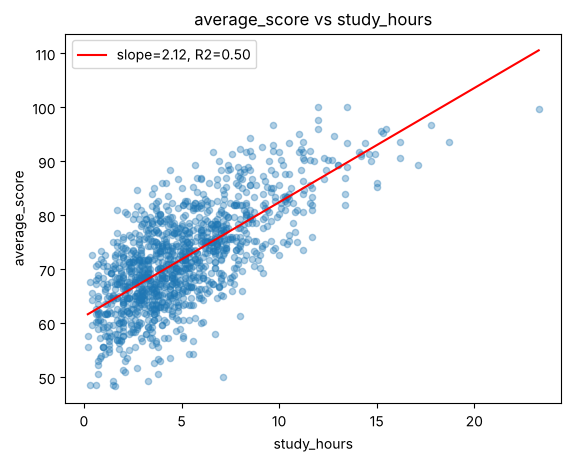

In [15]:
slope, intercept = np.polyfit(df.study_hours, df.average_score, 1)
r2 = np.corrcoef(df.study_hours, df.average_score)[0, 1] ** 2
print(f'slope = {slope:.2f} points per extra weekly study hour | intercept = {intercept:.1f} | R^2 = {r2:.3f}')
ax = df.plot(kind='scatter', x='study_hours', y='average_score', alpha=.35, title='average_score vs study_hours')
xs = np.linspace(df.study_hours.min(), df.study_hours.max(), 100)
ax.plot(xs, slope * xs + intercept, color='red', label=f'slope={slope:.2f}, R2={r2:.2f}'); ax.legend()
plt.savefig('trend_score_vs_study_hours.png', dpi=120, bbox_inches='tight'); plt.show()

Saved: `trend_score_vs_study_hours.png`. **Meaning:** on average, each extra weekly study hour is associated with about 2.1 more points on the average score. **Limitation:** R² is about 0.50, so half of the variation is unexplained, and the straight line mixes in attendance and school type (confounders) and would overpredict near the 100-point ceiling, so it should not be used to predict an individual student's score.

### 5b. Are the school-type and county differences real?
Permutation tests with numpy (10,000 shuffles for school type, 5,000 for county). H0: the label has no relationship with the outcome.

In [ ]:
rng = np.random.default_rng(55)
vals = df.average_score.values; is_priv = (df.school_type == 'Private').values
obs = vals[is_priv].mean() - vals[~is_priv].mean()
perm = np.array([(lambda p: vals[p].mean() - vals[~p].mean())(rng.permutation(is_priv)) for _ in range(10000)])
p_school = (1 + (np.abs(perm) >= abs(obs)).sum()) / (len(perm) + 1)
print(f'School type: observed gap = {obs:.2f} points | p-value = {p_school:.4f}')
risk_flag = df.at_risk.values; counties = df.county.values
def spread(lbl): g = pd.Series(risk_flag).groupby(lbl).mean(); return g.max() - g.min()
obs_c = spread(counties)
perm_c = np.array([spread(rng.permutation(counties)) for _ in range(5000)])
p_county = (1 + (perm_c >= obs_c).sum()) / (len(perm_c) + 1)
print(f'County At Risk spread (max-min share) = {obs_c*100:.1f} pts | p-value = {p_county:.3f}')
clean = df[(df.study_hours >= lo) & (df.study_hours <= hi)]
s2, _ = np.polyfit(clean.study_hours, clean.average_score, 1)
print(f'Slope without the {len(outl)} study_hours outliers = {s2:.2f} (full data: {slope:.2f})')

The school-type gap of about 5.5 points is far larger than chance (p < 0.001). The county differences in At Risk share are **well within what random variation would produce** (p is about 0.9), so we cannot say any county is genuinely worse. The study-hours slope is stable when the 29 outliers are removed (about 2.2 versus 2.1).

## Findings
1. **Only 8.2% of learners (99 of 1,200) are At Risk;** 56.0% are Meeting and 35.8% Exceeding, with an average score of 72.
2. **Study hours is the strongest genuine factor:** r = 0.70, about +2.1 points per extra weekly hour (R² about 0.50), and the slope is robust to outliers.
3. **Attendance matters moderately:** r = 0.36. Learners attending under 70% of the time are 24% At Risk versus 2% at 85%+.
4. **Risk is concentrated in Public schools and low-effort groups:** 94 of 99 At Risk learners are in Public schools, and 66 are in the lowest study-hours quartile. Private schools average about 5.5 points higher, and the gap persists in every attendance band and study quartile.
5. **County and gender do not separate learners:** Nairobi has the highest At Risk share (9.2%) but this and the other county differences are consistent with chance (p about 0.9), and gender averages differ by 0.2 points.

## Recommendations
1. **Target by learner profile, not by county.** County gaps are indistinguishable from noise, so enrol Public-school learners with low study hours (lowest quartile) and attendance below 70%, the group where about 60% are At Risk.
2. **Pair attendance follow-up with structured study support** (supervised homework time, study clubs), since study hours and attendance are the two measurable factors linked to scores. Track At Risk share in the programme group over a term to test whether it works.

## Limitations
This is observational, cross-sectional data, so associations (study hours, attendance, school type) are not proof of cause; for instance, higher-scoring students may also study more. Unmeasured factors such as household income, prior attainment and teacher quality may drive the Public-Private gap. At Risk counts are small (99 learners; 13-19 per county), so county comparisons are unstable. Scores are capped at 100, which compresses the top end, and the linear trend ignores this. There are no dates, so we cannot study change over time. Findings describe this dataset of 1,200 students and should be validated before a final budget decision.